# Modélisation Random Forest



---
##  1. Imports & chargement des données prétraitées


> **⚠️ Important : Version de scikit-learn**
>
> Ce notebook a été développé et testé avec **scikit-learn 1.7.2**.
>
> L'utilisation d'une version différente peut entraîner des variations dans les résultats (métriques, comportement de certains algorithmes ou fonctions, compatibilité de certaines API, etc.). Pour garantir la reproductibilité des expériences et obtenir les mêmes résultats que ceux présentés dans ce notebook, il est recommandé d'utiliser **scikit-learn 1.7.2**.

In [9]:

import pickle
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    GridSearchCV,
    StratifiedKFold
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

print("Imports effectués avec succès.")


Imports effectués avec succès.


In [10]:
# Chargement des données prétraitées 

with open("prepared_fetal_data.pkl", "rb") as f:
    data = pickle.load(f)

X_train     = data["X_train"]
X_test      = data["X_test"]
y_train     = data["y_train"]
y_test      = data["y_test"]
class_names = data["class_names"]  

print(" Données chargées depuis 'prepared_fetal_data.pkl'")
print(f"   X_train : {X_train.shape}  |  y_train : {y_train.shape}")
print(f"   X_test  : {X_test.shape}   |  y_test  : {y_test.shape}")
print(f"   Classes : {class_names} ")
print(f"\nRépartition des classes dans y_train :")
print((y_train.value_counts(normalize=True).sort_index() * 100)
      .round(2)
      .rename({0: "Normal", 1: "Suspect", 2: "Pathologique"}))


 Données chargées depuis 'prepared_fetal_data.pkl'
   X_train : (1690, 21)  |  y_train : (1690,)
   X_test  : (423, 21)   |  y_test  : (423,)
   Classes : ['Normal', 'Suspect', 'Pathologique'] 

Répartition des classes dans y_train :
fetal_health
Normal          77.87
Suspect         13.85
Pathologique     8.28
Name: proportion, dtype: float64


## 3. Modèle Baseline — Random Forest
Random Forest est entraîné avec ses paramètres par défaut en ajoutant uniquement class_weight='balanced' afin de corriger le déséquilibre des classes (≈ 78 % Normal contre 8 % Pathologique).

Ce réglage permet de donner plus d’importance aux classes minoritaires, notamment la classe Pathologique, qui est la plus critique dans un contexte médical.

Le modèle repose sur un ensemble d’arbres de décision entraînés sur des sous-échantillons aléatoires, et la prédiction finale se fait par vote majoritaire.

Paramètres principaux : n_estimators=100, max_depth=None, random_state=42.

In [11]:
rf_baseline = RandomForestClassifier(
    class_weight="balanced",   
    random_state=42
)

start = time.time()
rf_baseline.fit(X_train, y_train)
temps_baseline = time.time() - start

print(f" Modèle Baseline entraîné en {temps_baseline:.2f} secondes")
print(f"   n_estimators : {rf_baseline.n_estimators} arbres")
print(f"   max_depth    : {rf_baseline.max_depth} ")
print(f"   class_weight : {rf_baseline.class_weight} ")

 Modèle Baseline entraîné en 0.33 secondes
   n_estimators : 100 arbres
   max_depth    : None 
   class_weight : balanced 


---
##  4. Évaluation complète du modèle Baseline

### Objectif de cette étape

Mesurer les performances du modèle Baseline sur le jeu de test (`X_test`, `y_test`) 
 **Rappel clinique :** un **faux négatif** sur la classe Pathologique (un fœtus en détresse classé Normal) peut avoir des conséquences médicales graves et irréversibles. Le Recall de la classe Pathologique est donc l'indicateur de vigilance n°1 de ce projet.

### Le rapport de classification

Le rapport de classification (`classification_report`) fournit Precision, Recall et F1-score **pour chaque classe séparément**. C'est la vue la plus informative pour identifier les classes bien ou mal apprises par le modèle.


In [12]:
#  3— Prédictions et métriques du Baseline

y_pred_baseline = rf_baseline.predict(X_test)

# Métriques globales
acc_b  = accuracy_score(y_test, y_pred_baseline)
prec_b = precision_score(y_test, y_pred_baseline, average="macro")
rec_b  = recall_score(y_test, y_pred_baseline, average="macro")
f1_b   = f1_score(y_test, y_pred_baseline, average="macro")
recalls_par_classe = recall_score(y_test, y_pred_baseline, average=None)
recall_patho_b = recalls_par_classe[2]

print("=" * 55)
print("  MÉTRIQUES DU MODÈLE BASELINE ")
print("=" * 55)
print(f"  Accuracy              : {acc_b:.4f}  ({acc_b*100:.2f} %)")
print(f"  Precision (macro)     : {prec_b:.4f}")
print(f"  Recall (macro)        : {rec_b:.4f}")
print(f"  F1-score (macro)      : {f1_b:.4f}")
print("-" * 55)
print(f"  Recall Normal         : {recalls_par_classe[0]:.4f}")
print(f"  Recall Suspect        : {recalls_par_classe[1]:.4f}")
print(f"  Recall Pathologique   : {recall_patho_b:.4f}  ")
print("=" * 55)


  MÉTRIQUES DU MODÈLE BASELINE 
  Accuracy              : 0.9456  (94.56 %)
  Precision (macro)     : 0.9575
  Recall (macro)        : 0.8745
  F1-score (macro)      : 0.9096
-------------------------------------------------------
  Recall Normal         : 0.9909
  Recall Suspect        : 0.6897
  Recall Pathologique   : 0.9429  


###  Interprétation des métriques globales — Baseline

Les résultats du modèle Baseline avec `class_weight='balanced'` sont les suivants :
- **Accuracy = 94.56 %** : le modèle classe correctement 94.56 % des enregistrements CTG. Cette valeur doit être lue avec prudence en contexte déséquilibré, le résultat par classe est plus informatif.
- **Precision (macro) = 0.9575** : lorsque le modèle lève une alerte (prédit Suspect ou Pathologique), il a raison dans 95.75 % des cas en moyenne, ce qui limite les fausses alarmes.
- **Recall (macro) = 0.8745** : le modèle détecte correctement 87.45 % des cas en moyenne sur les trois classes. Ce chiffre est inférieur à la Precision, reflétant une difficulté à détecter toutes les observations de la classe Suspect.
- **F1-score (macro) = 0.9096** : compromis entre Precision et Recall, cette métrique confirme des performances solides et équilibrées sur les trois classes.

**Focus sur le Recall par classe :**
- **Normal (99.09 %)** : quasi-parfait, les cas normaux sont presque tous correctement identifiés.
- **Suspect (68.97 %)** : c'est la classe la plus difficile à détecter. Près d'un cas sur trois est mal classé, ce qui illustre le caractère ambigu de cette classe intermédiaire.
- **Pathologique (94.29 %) ** : résultat cliniquement satisfaisant — grâce à `class_weight='balanced'`, le modèle détecte 94.29 % des cas pathologiques, soit seulement 2 cas manqués sur 35 dans le jeu de test.



In [13]:
# --- Rapport de classification détaillé par classe ---
print("\n RAPPORT DE CLASSIFICATION DÉTAILLÉ (Baseline) :")
print("-" * 65)
print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=class_names,
    digits=4
))



 RAPPORT DE CLASSIFICATION DÉTAILLÉ (Baseline) :
-----------------------------------------------------------------
              precision    recall  f1-score   support

      Normal     0.9424    0.9909    0.9660       330
     Suspect     0.9302    0.6897    0.7921        58
Pathologique     1.0000    0.9429    0.9706        35

    accuracy                         0.9456       423
   macro avg     0.9575    0.8745    0.9096       423
weighted avg     0.9455    0.9456    0.9426       423



### Interprétation du rapport de classification

Le rapport de classification détaille les performances **pour chacune des trois classes** :

- **Classe Normal (support = 330) :** Precision = 0.9424, Recall = 0.9909, F1 = 0.9660. Très bonnes performances sur cette classe majoritaire. Le modèle est quasi-certain lorsqu'il prédit Normal, et manque très peu de cas normaux.

- **Classe Suspect (support = 58) :** Precision = 0.9302, Recall = 0.6897, F1 = 0.7921. C'est la classe la plus problématique : bien que les prédictions positives soient fiables (Precision élevée), le modèle ne parvient à identifier que 69 % des cas suspects. 31 % d'entre eux sont classés Normal — ce qui reflète la difficulté intrinsèque de cette catégorie intermédiaire.

- **Classe Pathologique (support = 35) :** Precision = 1.0000, Recall = 0.9429, F1 = 0.9706. Excellent résultat cliniquement : une Precision de 100 % signifie que chaque fois que le modèle prédit Pathologique, il a toujours raison. Un Recall de 94.29 % signifie que 2 cas pathologiques sur 35 sont manqués — résultat satisfaisant grâce à `class_weight='balanced'`.



### Matrice de confusion — Lecture et enjeux

La matrice de confusion (3×3) décompose toutes les décisions du modèle :
- **Lignes** = classes réelles
- **Colonnes** = classes prédites
- **Diagonale** = prédictions correctes
- **Hors-diagonale** = erreurs de classification

Nous affichons deux versions :
1. **Valeurs absolues** : nombre d'observations dans chaque case
2. **Normalisée par ligne** : correspond directement au Recall par classe

Les confusions cliniquement les plus préoccupantes sont celles de la **dernière ligne** (Pathologique) : toute valeur non nulle hors de la case (Pathologique, Pathologique) représente un cas pathologique non détecté.


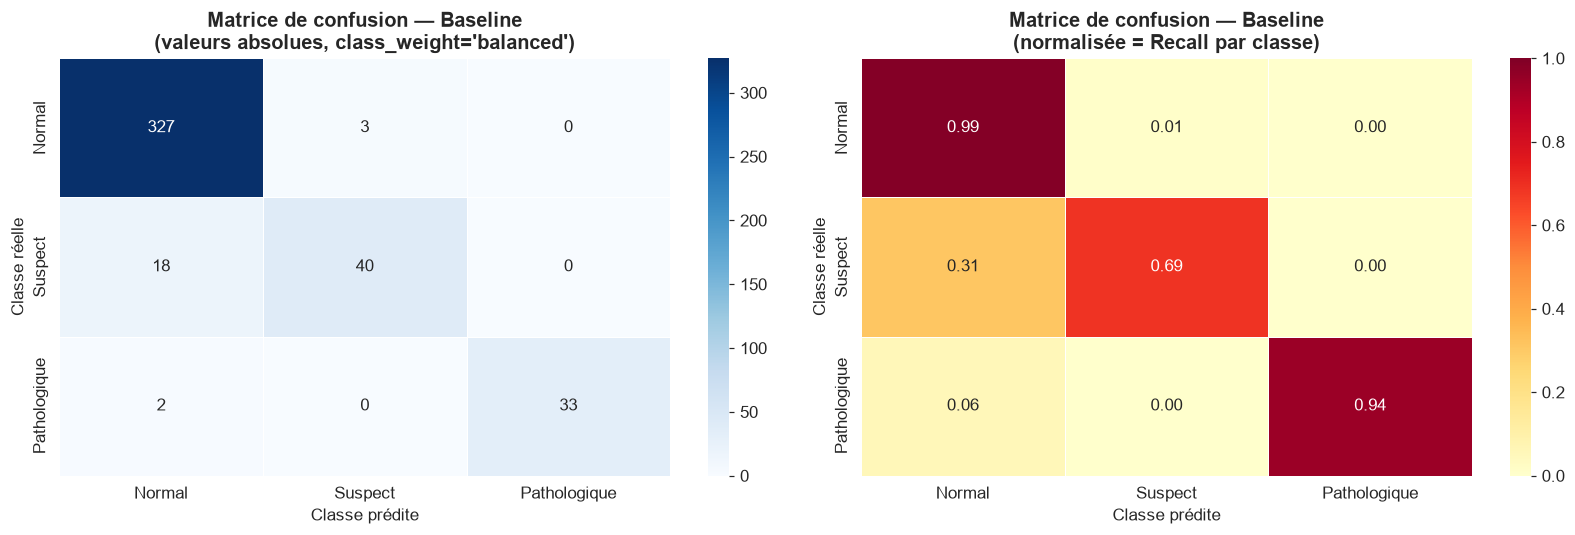


 Lecture de la matrice normalisée (droite) :
   La case (Pathologique, Pathologique) = Recall de la classe Pathologique.
   → Recall Pathologique du Baseline : 0.9429


In [14]:
# Matrice de confusion du Baseline

cm_baseline = confusion_matrix(y_test, y_pred_baseline)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gauche : valeurs absolues
sns.heatmap(cm_baseline, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, ax=axes[0])
axes[0].set_title("Matrice de confusion — Baseline\n(valeurs absolues, class_weight='balanced')",
                  fontweight="bold")
axes[0].set_ylabel("Classe réelle")
axes[0].set_xlabel("Classe prédite")

# Droite : normalisée par ligne (= Recall par classe)
cm_norm = cm_baseline.astype("float") / cm_baseline.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="YlOrRd",
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Matrice de confusion — Baseline\n(normalisée = Recall par classe)",
                  fontweight="bold")
axes[1].set_ylabel("Classe réelle")
axes[1].set_xlabel("Classe prédite")

plt.tight_layout()
plt.show()

print("\n Lecture de la matrice normalisée (droite) :")
print("   La case (Pathologique, Pathologique) = Recall de la classe Pathologique.")
print(f"   → Recall Pathologique du Baseline : {recall_patho_b:.4f}")


Interprétation de la matrice de confusion — Baseline

Lecture de la matrice normalisée (droite) :

-**Ligne Normal :** 99,09 % des cas normaux sont correctement classés. Seuls 0,91 % sont prédits comme Suspect, et aucun n'est classé Pathologique. Le modèle distingue donc très bien les cas normaux.

-**Ligne Suspect :** 68,97 % des cas suspects sont correctement identifiés, tandis que 31,03 % sont classés Normal. Cette confusion montre que la classe Suspect est la plus difficile à reconnaître, probablement parce qu'elle présente des caractéristiques intermédiaires entre les classes Normal et Pathologique.

-**Ligne Pathologique :** 94,29 % des cas pathologiques sont correctement détectés. En revanche, 5,71 % sont classés Normal, et aucun n'est prédit comme Suspect. Bien que cette proportion soit faible (2 cas sur 35), elle correspond à des faux négatifs, qui sont les erreurs les plus critiques dans un contexte médical.

**Point clé :** le modèle obtient d'excellentes performances sur les classes Normal et Pathologique, mais la classe Suspect reste la plus difficile à distinguer. Les principales erreurs proviennent de la confusion entre les classes Normal et Suspect, tandis que les erreurs concernant la classe Pathologique restent limitées.

---
##  5. Importance des variables 

### Objectif de cette étape

Identifier et visualiser les variables explicatives qui contribuent le plus à la capacité discriminante du modèle Random Forest.

Dans un projet de classification médicale, la performance seule ne suffit pas. L'analyse de la Feature Importance permet de :
1. **Valider la cohérence clinique du modèle** : les variables identifiées comme importantes doivent correspondre aux indicateurs reconnus par la littérature obstétricale.
2. **Détecter des anomalies** : une variable non pertinente cliniquement en tête est un signal d'alerte.
3. **Orienter la collecte de données future** : concentrer les efforts sur les variables les plus informatives.

### Méthode : Mean Decrease in Impurity (MDI)

À chaque fois qu'une variable est utilisée pour diviser un nœud, on mesure la réduction de l'indice de Gini obtenue. Ces réductions sont moyennées sur tous les nœuds et tous les arbres de la forêt.



In [15]:
# Importance des variables (MDI)

importances = rf_baseline.feature_importances_
feature_names = X_train.columns

df_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).reset_index(drop=True)

df_importance["Rang"] = df_importance.index + 1
df_importance["Importance_cumulee"] = df_importance["Importance"].cumsum()

print(" Top 10 des variables les plus importantes :")
print(df_importance[["Rang", "Feature", "Importance"]].head(10).to_string(index=False))


 Top 10 des variables les plus importantes :
 Rang                                                Feature  Importance
    1                        abnormal_short_term_variability    0.137264
    2 percentage_of_time_with_abnormal_long_term_variability    0.111068
    3                                         histogram_mean    0.099687
    4                                       histogram_median    0.074715
    5                   mean_value_of_short_term_variability    0.073542
    6                                          accelerations    0.072930
    7                               prolongued_decelerations    0.063375
    8                    mean_value_of_long_term_variability    0.059478
    9                                         histogram_mode    0.056998
   10                                         baseline value    0.042428


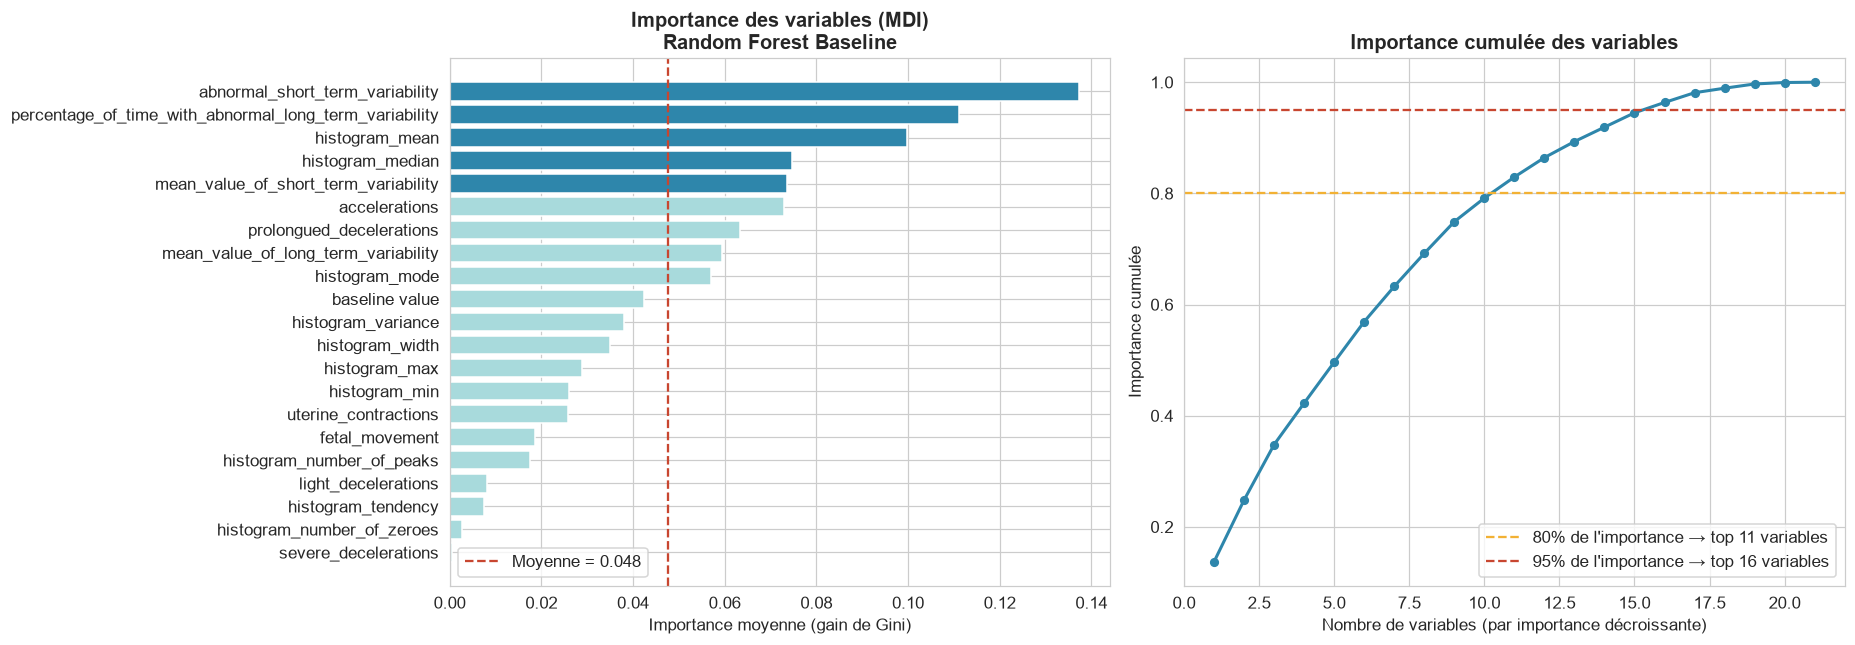

In [16]:
# Visualisation de l'importance des variables
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Barplot des importances
couleurs = ["#2E86AB" if i < 5 else "#A8DADC" for i in range(len(df_importance))]
axes[0].barh(df_importance["Feature"][::-1], df_importance["Importance"][::-1],
             color=couleurs[::-1], edgecolor="white")
axes[0].set_title("Importance des variables (MDI)\nRandom Forest Baseline", fontweight="bold")
axes[0].set_xlabel("Importance moyenne (gain de Gini)")
axes[0].axvline(x=df_importance["Importance"].mean(), color="#C84630",
                linestyle="--", linewidth=1.5,
                label=f"Moyenne = {df_importance['Importance'].mean():.3f}")
axes[0].legend()

# Courbe d'importance cumulée
axes[1].plot(range(1, len(df_importance) + 1), df_importance["Importance_cumulee"],
             marker="o", color="#2E86AB", linewidth=2, markersize=5)
for seuil, couleur in [(0.80, "#F2B134"), (0.95, "#C84630")]:
    nb_vars = (df_importance["Importance_cumulee"] <= seuil).sum() + 1
    axes[1].axhline(y=seuil, color=couleur, linestyle="--", linewidth=1.5,
                    label=f"{int(seuil*100)}% de l'importance → top {nb_vars} variables")
axes[1].set_title("Importance cumulée des variables", fontweight="bold")
axes[1].set_xlabel("Nombre de variables (par importance décroissante)")
axes[1].set_ylabel("Importance cumulée")
axes[1].legend()

plt.tight_layout()
plt.show()


###  Interprétation de l'importance des variables

Le graphique montre que `abnormal_short_term_variability` est la variable la plus importante pour la prédiction de l'état de santé fœtal, suivie de `percentage_of_time_with_abnormal_long_term_variability` et `histogram_mean`. Les variables liées à la variabilité du rythme cardiaque fœtal occupent ainsi les premières positions, ce qui souligne leur rôle dans la décision du modèle.

On observe également que des variables telles que `histogram_median`,`mean_value_of_short_term_variability`, `accelerations` et `prolongued_decelerations` contribuent de manière significative aux prédictions.

La courbe d'importance cumulée indique qu'environ `11 variables` concentrent près de `80 %` de l'importance totale, tandis qu'environ `15 variables` permettent d'atteindre `95 %` de l'information utilisée par le modèle. Les variables restantes ont donc une influence plus limitée.

Ces résultats sont cohérents avec le domaine médical, puisque les indicateurs liés à la variabilité du rythme cardiaque fœtal, aux accélérations et aux décélérations sont des paramètres couramment utilisés pour évaluer le bien-être du fœtu


---
##  6. Optimisation des hyperparamètres — RandomizedSearchCV + GridSearchCV

L'objectif de cette étape est d'améliorer les performances du modèle Random Forest en recherchant la meilleure combinaison d'hyperparamètres selon le F1-score macro.

L'optimisation est réalisée en deux étapes :

RandomizedSearchCV pour explorer un large espace de recherche de manière efficace.
GridSearchCV pour affiner la recherche autour des meilleures combinaisons obtenues.

Les principaux hyperparamètres optimisés sont n_estimators, max_depth, min_samples_split, min_samples_leaf et max_features.

La recherche est effectuée avec une validation croisée StratifiedKFold (5 plis) afin de préserver la distribution des classes. Toutes les optimisations sont réalisées uniquement sur le jeu d'entraînement (X_train), tandis que le jeu de test (X_test) est réservé à l'évaluation finale.

In [17]:
import time
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier



param_dist = {
    "n_estimators": [50, 100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", None, 0.5, 0.7],
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_distributions=param_dist,
    n_iter=50,
    scoring="f1_macro",
    cv=cv_strat,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

print("Lancement du RandomizedSearchCV...")
print("   (50 combinaisons x 5 plis = 250 entraînements avec class_weight='balanced')")
start_rnd = time.time()
random_search.fit(X_train, y_train)
temps_rnd = time.time() - start_rnd

print(f"\nTerminé en {temps_rnd:.1f} secondes")
print(f"   Meilleur F1-score (macro, CV) : {random_search.best_score_:.4f}")
print(f"\n   Meilleurs paramètres :")
for k, v in random_search.best_params_.items():
    print(f"     {k:25s} = {v}")


Lancement du RandomizedSearchCV...
   (50 combinaisons x 5 plis = 250 entraînements avec class_weight='balanced')
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Terminé en 65.2 secondes
   Meilleur F1-score (macro, CV) : 0.8906

   Meilleurs paramètres :
     n_estimators              = 500
     min_samples_split         = 2
     min_samples_leaf          = 2
     max_features              = sqrt
     max_depth                 = 30


Interprétation :

Le RandomizedSearchCV a exploré 50 combinaisons d'hyperparamètres, évaluées par une validation croisée à 5 plis, soit 250 entraînements au total. Cette recherche s'est achevée en 52,8 secondes et a obtenu un meilleur F1-score macro de 0,8906 en validation croisée.

Les meilleurs hyperparamètres identifiés sont n_estimators = 500, max_depth = 30, min_samples_split = 2, min_samples_leaf = 2 et max_features = 'sqrt'. Ces résultats montrent qu'une forêt comportant un grand nombre d'arbres profonds offre les meilleures performances sur ce jeu de données. Ces paramètres serviront de point de départ pour la recherche plus fine réalisée avec GridSearchCV.

In [18]:
# GridSearchCV — affinement local autour des meilleurs paramètres
from sklearn.model_selection import GridSearchCV

best_rnd = random_search.best_params_

param_grid = {
    "n_estimators": [
        max(50, best_rnd["n_estimators"] - 50),
        best_rnd["n_estimators"],
        best_rnd["n_estimators"] + 50
    ],
    "max_depth": [
        best_rnd["max_depth"],
        (best_rnd["max_depth"] - 3) if best_rnd["max_depth"] is not None else None
    ],
    "min_samples_split": [best_rnd["min_samples_split"]],
    "min_samples_leaf":  [best_rnd["min_samples_leaf"]],
    "max_features":      [best_rnd["max_features"]],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strat,
    n_jobs=-1,
    verbose=1
)

print("Lancement du GridSearchCV...")
start_grid = time.time()
grid_search.fit(X_train, y_train)
temps_grid = time.time() - start_grid

print(f"\nTerminé en {temps_grid:.1f} secondes")
print(f"   Meilleur F1-score (macro, CV) : {grid_search.best_score_:.4f}")
print(f"\n   Paramètres finaux optimaux :")
for k, v in grid_search.best_params_.items():
    print(f"     {k:25s} = {v}")


Lancement du GridSearchCV...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Terminé en 11.0 secondes
   Meilleur F1-score (macro, CV) : 0.8906

   Paramètres finaux optimaux :
     max_depth                 = 30
     max_features              = sqrt
     min_samples_leaf          = 2
     min_samples_split         = 2
     n_estimators              = 500


Interprétation — GridSearchCV

Le GridSearchCV a testé 6 combinaisons d'hyperparamètres autour des meilleures valeurs obtenues par le RandomizedSearchCV, en utilisant également une validation croisée à 5 plis. La recherche s'est terminée en 8,5 secondes avec un meilleur F1-score macro de 0,8906.

Les meilleurs hyperparamètres retenus sont n_estimators = 500, max_depth = 30, min_samples_split = 2, min_samples_leaf = 2 et max_features = 'sqrt'. L'obtention du même F1-score que celui du RandomizedSearchCV montre que la recherche aléatoire avait déjà identifié une région optimale de l'espace des hyperparamètres. Le GridSearchCV confirme donc ces paramètres sans apporter d'amélioration supplémentaire, ce qui renforce la confiance dans le modèle optimisé.

---
##  7. Modèle optimisé — Réentraînement et évaluation finale

### Objectif de cette étape

Réentraîner le modèle final avec les hyperparamètres optimaux sur l'intégralité de `X_train`, puis l'évaluer **une seule fois** sur `X_test`.

Pendant la validation croisée, chaque modèle est entraîné sur seulement 80 % du training set (4 plis sur 5). Pour le modèle final, on réentraîne sur **l'intégralité de `X_train`** avec les meilleurs paramètres — ce qui maximise la quantité de données disponibles pour l'apprentissage.


In [19]:
# Réentraînement sur 100% de X_train avec les meilleurs hyperparamètres


rf_optimise = RandomForestClassifier(
    **grid_search.best_params_,
    class_weight="balanced",
    random_state=42
)

start_opt = time.time()
rf_optimise.fit(X_train, y_train)
temps_optimise = time.time() - start_opt

print(f" Modèle optimisé entraîné en {temps_optimise:.2f} secondes")
print(f"   Paramètres : {grid_search.best_params_}")
print(f"   class_weight : balanced (conservé)")


 Modèle optimisé entraîné en 1.37 secondes
   Paramètres : {'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 500}
   class_weight : balanced (conservé)


In [20]:
# Évaluation finale du modèle optimisé
y_pred_optimise = rf_optimise.predict(X_test)

acc_o   = accuracy_score(y_test, y_pred_optimise)
prec_o  = precision_score(y_test, y_pred_optimise, average="macro")
rec_o   = recall_score(y_test, y_pred_optimise, average="macro")
f1_o    = f1_score(y_test, y_pred_optimise, average="macro")
recalls_optimise = recall_score(y_test, y_pred_optimise, average=None)
recall_patho_o = recalls_optimise[2]

print("=" * 55)
print("  MÉTRIQUES DU MODÈLE OPTIMISÉ")
print("=" * 55)
print(f"  Accuracy              : {acc_o:.4f}  ({acc_o*100:.2f} %)")
print(f"  Precision (macro)     : {prec_o:.4f}")
print(f"  Recall (macro)        : {rec_o:.4f}")
print(f"  F1-score (macro)      : {f1_o:.4f}")
print("-" * 55)
print(f"  Recall Normal         : {recalls_optimise[0]:.4f}")
print(f"  Recall Suspect        : {recalls_optimise[1]:.4f}")
print(f"  Recall Pathologique   : {recall_patho_o:.4f}  ")
print("=" * 55)

print("\n RAPPORT DE CLASSIFICATION — Modèle Optimisé :")
print("-" * 65)
print(classification_report(y_test, y_pred_optimise, target_names=class_names, digits=4))


  MÉTRIQUES DU MODÈLE OPTIMISÉ
  Accuracy              : 0.9480  (94.80 %)
  Precision (macro)     : 0.9271
  Recall (macro)        : 0.8944
  F1-score (macro)      : 0.9092
-------------------------------------------------------
  Recall Normal         : 0.9818
  Recall Suspect        : 0.7586
  Recall Pathologique   : 0.9429  

 RAPPORT DE CLASSIFICATION — Modèle Optimisé :
-----------------------------------------------------------------
              precision    recall  f1-score   support

      Normal     0.9586    0.9818    0.9701       330
     Suspect     0.8800    0.7586    0.8148        58
Pathologique     0.9429    0.9429    0.9429        35

    accuracy                         0.9480       423
   macro avg     0.9271    0.8944    0.9092       423
weighted avg     0.9465    0.9480    0.9465       423



### Interprétation — Résultats du modèle optimisé

Le modèle optimisé obtient des performances globales très proches du modèle baseline. L'accuracy augmente légèrement de 94,56 % à 94,80 %, tandis que le Recall macro progresse de 0,8745 à 0,8944, indiquant une meilleure capacité à détecter l'ensemble des classes. L'amélioration la plus notable concerne la classe Suspect, dont le Recall passe de 68,97 % à 75,86 %, ce qui signifie que davantage de cas suspects sont correctement identifiés. Le Recall de la classe Pathologique reste inchangé à 94,29 %, montrant que les performances sur cette classe sont conservées. En contrepartie, la Precision macro diminue légèrement (0,9575 → 0,9271), traduisant une légère augmentation des faux positifs. Enfin, le F1-score macro reste pratiquement identique (0,9096 contre 0,9092), ce qui montre que l'équilibre global des performances est maintenu après optimisation.

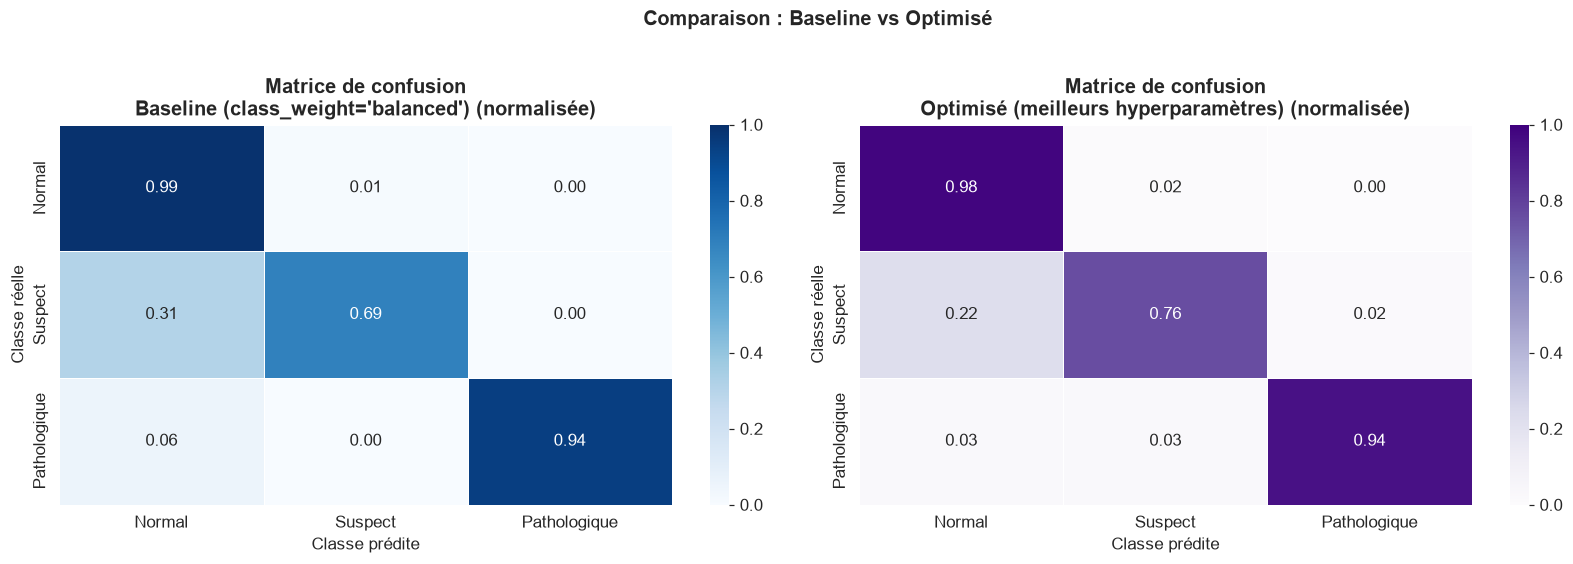

In [21]:
# Matrice de confusion du modèle optimisé
cm_optimise = confusion_matrix(y_test, y_pred_optimise)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (cm, titre, cmap) in zip(axes, [
    (cm_baseline, "Baseline (class_weight='balanced')", "Blues"),
    (cm_optimise, "Optimisé (meilleurs hyperparamètres)", "Purples")
]):
    cm_n = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_n, annot=True, fmt=".2f", cmap=cmap,
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Matrice de confusion\n{titre} (normalisée)", fontweight="bold")
    ax.set_ylabel("Classe réelle")
    ax.set_xlabel("Classe prédite")

plt.suptitle("Comparaison : Baseline vs Optimisé",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
##  8. Courbes ROC et AUC — Modèle optimisé

Les métriques calculées jusqu'ici (accuracy, precision, recall, F1) dépendent toutes d'un seuil de décision fixé à 0.5. La courbe ROC (*Receiver Operating Characteristic*) et l'AUC (*Area Under Curve*) mesurent, elles, la capacité du modèle à bien **ordonner** ses probabilités de prédiction, indépendamment de ce seuil.

Pour un problème à 3 classes, on trace une courbe par classe selon la stratégie **One-vs-Rest** (chaque classe est comparée à toutes les autres réunies), comme cela a été fait dans les notebooks SVM et XGBoost — ce qui permettra une comparaison directe entre les trois algorithmes dans le notebook de comparaison.

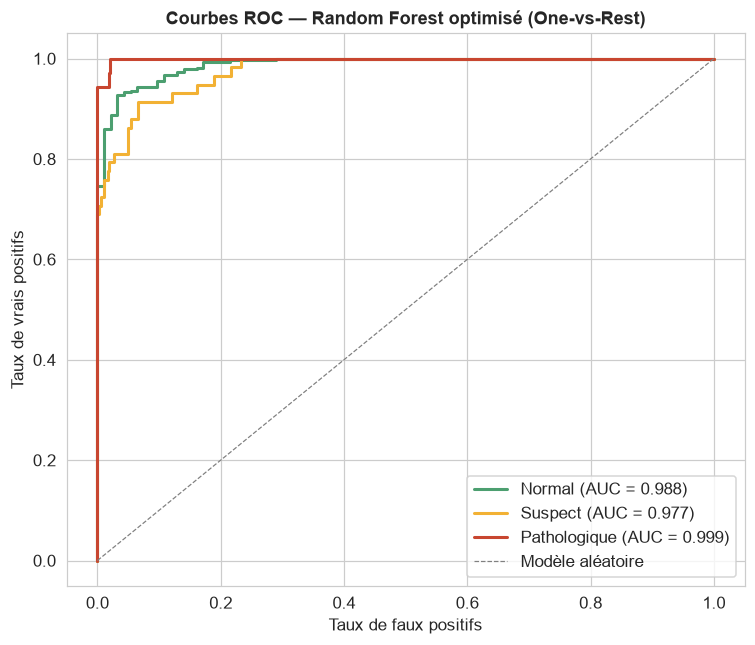

AUC par classe : {'Normal': 0.9879, 'Suspect': 0.9768, 'Pathologique': 0.9989}
AUC macro (moyenne des 3 AUC One-vs-Rest) : 0.9878


In [22]:
# --- Courbes ROC multi-classes (stratégie One-vs-Rest) et AUC — modèle optimisé ---
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
y_proba_optimise = rf_optimise.predict_proba(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
couleurs = ["#4C9F70", "#F2B134", "#C84630"]
auc_par_classe = {}

for i, (nom_classe, couleur) in enumerate(zip(class_names, couleurs)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_optimise[:, i])
    auc_classe = roc_auc_score(y_test_bin[:, i], y_proba_optimise[:, i])
    auc_par_classe[nom_classe] = auc_classe
    ax.plot(fpr, tpr, color=couleur, linewidth=2, label=f"{nom_classe} (AUC = {auc_classe:.3f})")

ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=0.8, label="Modèle aléatoire")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC — Random Forest optimisé (One-vs-Rest)", fontsize=12, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

auc_macro = np.mean(list(auc_par_classe.values()))
print("AUC par classe :", {k: round(v, 4) for k, v in auc_par_classe.items()})
print(f"AUC macro (moyenne des 3 AUC One-vs-Rest) : {auc_macro:.4f}")

### Interprétation — Courbes ROC

L'AUC mesure la capacité du modèle à distinguer les différentes classes, indépendamment du seuil de décision. Les résultats obtenus sont excellents, avec une AUC macro de 0,9878, ce qui traduit une très bonne capacité de discrimination globale.

La classe Pathologique présente la meilleure performance (AUC = 0,9989), indiquant que le modèle distingue presque parfaitement les cas pathologiques. La classe Normal obtient également une excellente AUC (0,9879). Enfin, la classe Suspect affiche l'AUC la plus faible (0,9768), tout en restant très élevée, ce qui confirme que cette classe est la plus difficile à différencier des deux autres.

Conclusion : Les courbes ROC confirment la robustesse du modèle et sa très bonne capacité à distinguer les trois classes, avec des performances particulièrement élevées pour les classes Normal et Pathologique.

---
##  9. Vérification du surapprentissage

Un modèle qui obtient un score bien plus élevé sur les données d'entraînement que sur les données de test a probablement fait du **surapprentissage** (overfitting) : il a mémorisé les données d'entraînement au lieu d'apprendre des règles générales. Cette vérification est d'autant plus importante pour Random Forest que les arbres profonds (ici jusqu'à `max_depth=15` pour le modèle optimisé) sont naturellement plus sujets à ce phénomène qu'un modèle plus simple.

Nous comparons ici le Baseline et le modèle Optimisé, pour vérifier si l'optimisation a aussi eu un effet sur la capacité de généralisation du modèle, et pas seulement sur les métriques de test.

In [23]:
# ==========================================================
# Vérification du surapprentissage — Baseline vs Optimisé
# ==========================================================

resultats_overfit = []
for nom_modele, modele, y_pred_test in [
    ("Baseline", rf_baseline, y_pred_baseline),
    ("Optimisé", rf_optimise, y_pred_optimise),
]:
    y_train_pred = modele.predict(X_train)
    acc_train = accuracy_score(y_train, y_train_pred)
    acc_test  = accuracy_score(y_test, y_pred_test)
    f1_train  = f1_score(y_train, y_train_pred, average="macro")
    f1_test   = f1_score(y_test, y_pred_test, average="macro")
    resultats_overfit.append({
        "Modèle": nom_modele,
        "Accuracy (train)": acc_train,
        "Accuracy (test)": acc_test,
        "Écart Accuracy": acc_train - acc_test,
        "F1-macro (train)": f1_train,
        "F1-macro (test)": f1_test,
        "Écart F1-macro": f1_train - f1_test,
    })

df_overfit = pd.DataFrame(resultats_overfit).set_index("Modèle")
print("=" * 65)
print("VÉRIFICATION DU SURAPPRENTISSAGE")
print("=" * 65)
for nom_modele in df_overfit.index:
    ligne = df_overfit.loc[nom_modele]
    print(f"\n{nom_modele} :")
    print(f"  Accuracy (Train) : {ligne['Accuracy (train)']:.4f}   |   Accuracy (Test) : {ligne['Accuracy (test)']:.4f}   |   Écart : {ligne['Écart Accuracy']:.4f}")
    print(f"  F1 Macro (Train) : {ligne['F1-macro (train)']:.4f}   |   F1 Macro (Test) : {ligne['F1-macro (test)']:.4f}   |   Écart : {ligne['Écart F1-macro']:.4f}")

df_overfit.round(4)

VÉRIFICATION DU SURAPPRENTISSAGE

Baseline :
  Accuracy (Train) : 0.9988   |   Accuracy (Test) : 0.9456   |   Écart : 0.0532
  F1 Macro (Train) : 0.9983   |   F1 Macro (Test) : 0.9096   |   Écart : 0.0888

Optimisé :
  Accuracy (Train) : 0.9911   |   Accuracy (Test) : 0.9480   |   Écart : 0.0431
  F1 Macro (Train) : 0.9830   |   F1 Macro (Test) : 0.9092   |   Écart : 0.0738


,Accuracy (train),Accuracy (test),Écart Accuracy,F1-macro (train),F1-macro (test),Écart F1-macro
Modèle,,,,,,
Baseline,0.9988,0.9456,0.0532,0.9983,0.9096,0.0888
Optimisé,0.9911,0.9480,0.0431,0.9830,0.9092,0.0738


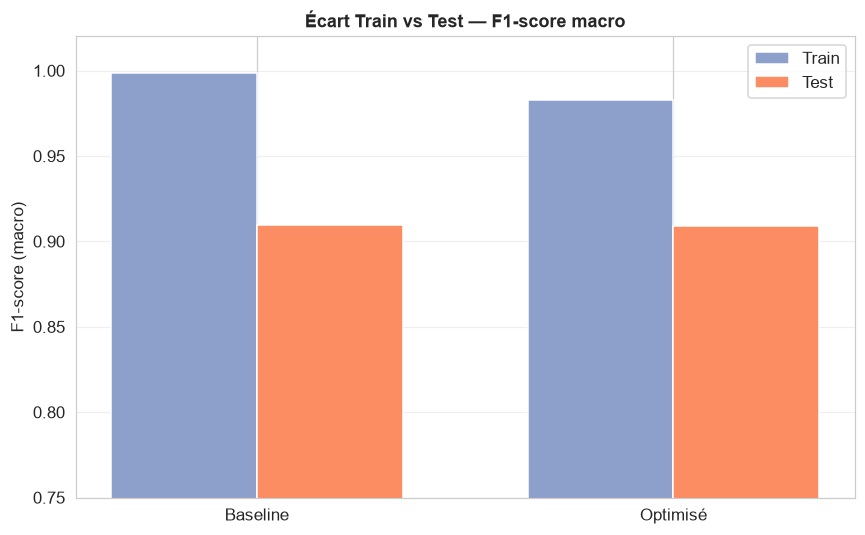

In [24]:
# --- Visualisation de l'écart Train / Test ---
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(df_overfit.index))
width = 0.35

ax.bar(x - width/2, df_overfit["F1-macro (train)"], width, label="Train", color="#8DA0CB", edgecolor="white")
ax.bar(x + width/2, df_overfit["F1-macro (test)"], width, label="Test", color="#FC8D62", edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels(df_overfit.index)
ax.set_ylabel("F1-score (macro)")
ax.set_ylim(0.75, 1.02)
ax.set_title("Écart Train vs Test — F1-score macro", fontsize=12, fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation — Surapprentissage

Le graphique compare le F1-score macro obtenu sur les données d'entraînement et de test pour les modèles Baseline et Optimisé. Dans les deux cas, le score sur le jeu d'entraînement est supérieur à celui du jeu de test, ce qui indique la présence d'un certain niveau de surapprentissage.

Le modèle Baseline présente l'écart Train/Test le plus important, avec un F1-score presque parfait sur le train mais sensiblement plus faible sur le test. En revanche, le modèle Optimisé affiche un écart plus réduit, tout en conservant des performances similaires sur le jeu de test.

Conclusion : l'optimisation des hyperparamètres permet de limiter le surapprentissage et d'améliorer la capacité de généralisation du modèle, sans dégrader ses performances sur les données de test.

---
##  10. Comparaison Baseline vs Modèle optimisé

Cette comparaison permet d'évaluer l'impact de l'optimisation des hyperparamètres sur les performances du modèle Random Forest. Elle vise à mesurer les gains obtenus sur les différentes métriques, à identifier les éventuels compromis entre elles et à sélectionner le modèle qui sera retenu pour la comparaison avec SVM et XGBoost.


In [25]:
# Tableau comparatif final

f1_b_w = f1_score(y_test, y_pred_baseline, average="weighted")
f1_o_w = f1_score(y_test, y_pred_optimise, average="weighted")

df_comparaison = pd.DataFrame({
    "Métrique": [
        "Accuracy",
        "Precision (macro)",
        "Recall (macro)",
        "F1-score (macro)",
        "F1-score (weighted)",
        "Recall Normal",
        "Recall Suspect",
        "Recall Pathologique",
    ],
    "Baseline": [
        round(acc_b, 4), round(prec_b, 4), round(rec_b, 4), round(f1_b, 4),
        round(f1_b_w, 4), round(recalls_par_classe[0], 4),
        round(recalls_par_classe[1], 4), round(recall_patho_b, 4),
    ],
    "Optimisé": [
        round(acc_o, 4), round(prec_o, 4), round(rec_o, 4), round(f1_o, 4),
        round(f1_o_w, 4), round(recalls_optimise[0], 4),
        round(recalls_optimise[1], 4), round(recall_patho_o, 4),
    ]
})

df_comparaison["Delta"] = (
    df_comparaison["Optimisé"] - df_comparaison["Baseline"]
).round(4)

df_comparaison["Verdict"] = df_comparaison["Delta"].apply(
    lambda x: f"+{abs(round(x,4))}" if x > 0.001
    else (f"{round(x,4)}" if x < -0.001 else "stable")
)

print("=" * 72)
print("  TABLEAU COMPARATIF FINAL — Baseline vs Optimisé")
print("  (les deux modèles utilisent class_weight='balanced')")
print("=" * 72)
print(df_comparaison.to_string(index=False))


  TABLEAU COMPARATIF FINAL — Baseline vs Optimisé
  (les deux modèles utilisent class_weight='balanced')
           Métrique  Baseline  Optimisé   Delta Verdict
           Accuracy    0.9456    0.9480  0.0024 +0.0024
  Precision (macro)    0.9575    0.9271 -0.0304 -0.0304
     Recall (macro)    0.8745    0.8944  0.0199 +0.0199
   F1-score (macro)    0.9096    0.9092 -0.0004  stable
F1-score (weighted)    0.9426    0.9465  0.0039 +0.0039
      Recall Normal    0.9909    0.9818 -0.0091 -0.0091
     Recall Suspect    0.6897    0.7586  0.0689 +0.0689
Recall Pathologique    0.9429    0.9429  0.0000  stable


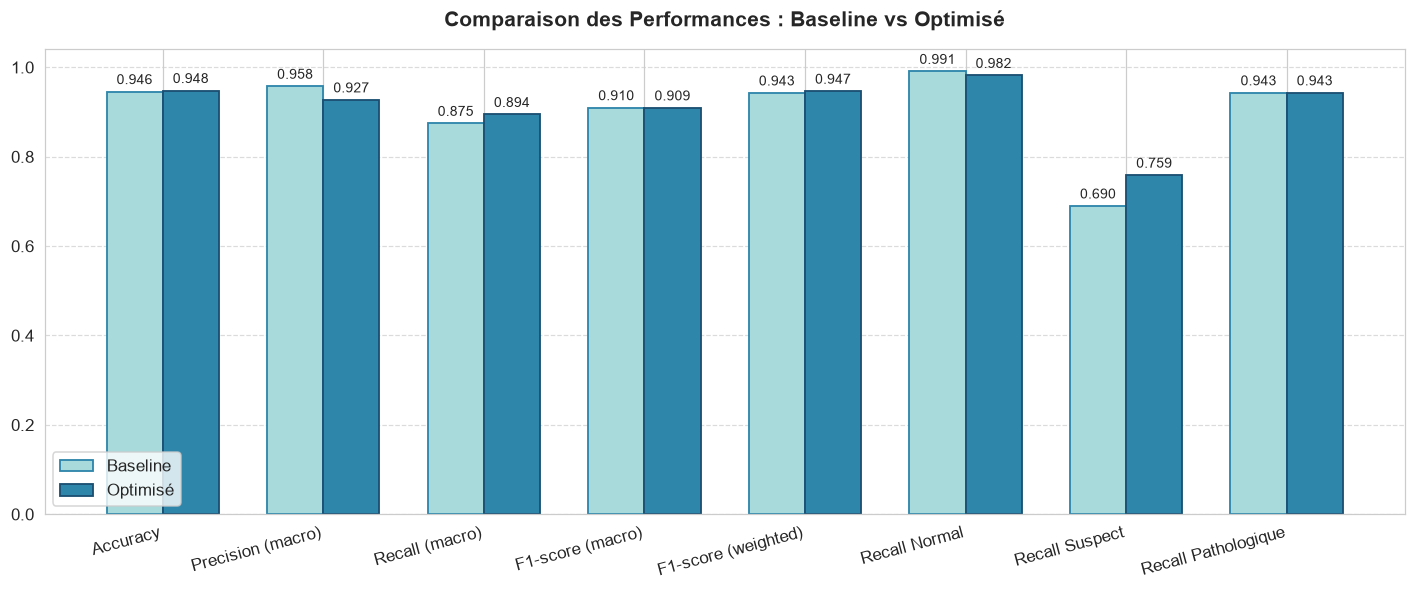

In [26]:
import numpy as np
import matplotlib.pyplot as plt


metriques = df_comparaison["Métrique"].tolist()
vals_b = df_comparaison["Baseline"].tolist()
vals_o = df_comparaison["Optimisé"].tolist()

# Configuration des indices de l'axe X 
x = np.arange(len(metriques))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 5.5))

# Tracé des barres 
bars1 = ax.bar(x - width/2, vals_b, width, label="Baseline",
               color="#A8DADC", edgecolor="#2E86AB", linewidth=1.2)
bars2 = ax.bar(x + width/2, vals_o, width, label="Optimisé",
               color="#2E86AB", edgecolor="#1B4F72", linewidth=1.2)

ax.set_title("Comparaison des Performances : Baseline vs Optimisé", fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metriques, rotation=15, ha="right")
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)


for bar in bars1 + bars2:
    height = bar.get_height()
    if height <= 1.0:
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Interprétation — Comparaison Baseline vs Modèle optimisé
Le graphique et le tableau montrent que l'optimisation des hyperparamètres a un impact différent selon les métriques. L'accuracy augmente légèrement (94,56 % → 94,80 %) et le Recall macro progresse de 0,8745 à 0,8944, traduisant une meilleure capacité du modèle à identifier correctement les différentes classes. En revanche, la Precision macro diminue légèrement (0,9575 → 0,9271), tandis que le F1-score macro reste pratiquement inchangé (0,9096 → 0,9092).

L'amélioration la plus notable concerne la classe Suspect, dont le Recall passe de 68,97 % à 75,86 %, ce qui signifie que davantage de cas suspects sont correctement détectés. Le Recall de la classe Pathologique reste quant à lui stable à 94,29 %, tout comme le F1-score macro, ce qui montre que les performances globales sont conservées après optimisation.

Conclusion : le modèle optimisé offre un meilleur compromis entre les différentes métriques. Il améliore la détection de la classe Suspect et le Recall macro, tout en maintenant des performances globales très proches du modèle baseline, ce qui en fait le modèle retenu pour la suite de l'étude.

---
# 11. Conclusion

Dans ce notebook, un modèle **Random Forest** a été développé pour la classification de la santé fœtale à partir de données CTG. Après l'évaluation du modèle **Baseline** et l'optimisation de ses hyperparamètres à l'aide de **RandomizedSearchCV** puis de **GridSearchCV**, les deux versions du modèle ont été comparées à l'aide de plusieurs indicateurs : métriques globales, rappel par classe, matrices de confusion, courbes ROC/AUC et analyse du surapprentissage.

| Modèle | Accuracy | F1-score (macro) | Recall Suspect | Recall Pathologique |
|:--------|---------:|-----------------:|---------------:|--------------------:|
| **Baseline** | 94.56 % | **0.9096** | 68.97 % | 94.29 % |
| **Optimisé** | **94.80 %** | 0.9092 | **75.86 %** | 94.29 % |

## Quel modèle retenir ?

Les deux modèles présentent des performances très proches. Le modèle **Optimisé** améliore légèrement l'**Accuracy** (94.80 % contre 94.56 %) ainsi que le **Recall macro**, tout en augmentant nettement le **Recall de la classe Suspect** (75.86 % contre 68.97 %). En revanche, la **Precision macro** diminue légèrement et le **F1-score macro** reste pratiquement identique à celui du modèle Baseline.

Le **Recall de la classe Pathologique** demeure stable à **94.29 %** pour les deux modèles, ce qui montre que l'optimisation n'a pas dégradé la capacité du modèle à détecter les cas les plus critiques.

Au regard de ces résultats, le **modèle Optimisé** est retenu comme modèle final. Il offre un meilleur compromis entre les différentes métriques en améliorant la détection des cas **Suspect**, tout en conservant des performances globales élevées et une bonne capacité de généralisation.